# Лабораторная работа №4 — Аугментация данных и трансферное обучение
## Дисциплина: Нейронные сети и глубокое обучение
**Датасет:** Собственный датасет (фрукты / овощи / ягоды)  
**Фреймворк:** Keras 3 (PyTorch backend) + ImageDataGenerator

---
## 0. Импорты и настройка

In [11]:
import os
os.environ['KERAS_BACKEND'] = 'torch'

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import random
import json
from datetime import datetime

import torch
import keras
from keras import layers
from keras.models import Sequential, Model
from keras.layers import Dense, Dropout, GlobalAveragePooling2D, Flatten
from keras.utils import to_categorical
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report

# ── GPU ──────────────────────────────────────────────────────────
print('Keras backend:', keras.backend.backend())
print('PyTorch CUDA:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12
sns.set_style('whitegrid')

Keras backend: torch
PyTorch CUDA: True
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


---
## 1. Пути и параметры

In [12]:
# ── Пути к данным (папка frukta рядом с ноутбуком) ───────────────
BASE_DIR   = os.path.dirname(os.path.abspath('__file__'))
TRAIN_PATH = os.path.join(BASE_DIR, 'frukta', 'train')
TEST_PATH  = os.path.join(BASE_DIR, 'frukta', 'test')

# ── Параметры ─────────────────────────────────────────────────────
IMG_SIZE   = 128      # канонический размер для VGG16/19
BATCH_SIZE = 16
EPOCHS     = 7
SEED       = 42

class_names = sorted([
    d for d in os.listdir(TRAIN_PATH)
    if os.path.isdir(os.path.join(TRAIN_PATH, d))
])
NUM_CLASSES = len(class_names)

print(f'Train: {TRAIN_PATH}')
print(f'Test:  {TEST_PATH}')
print(f'Классы ({NUM_CLASSES}): {class_names}')
print(f'Размер изображений: {IMG_SIZE}×{IMG_SIZE}')

Train: c:\Users\Пользователь\Desktop\програмироание\Нейронные-сети--глубокое-обучение\frukta\train
Test:  c:\Users\Пользователь\Desktop\програмироание\Нейронные-сети--глубокое-обучение\frukta\test
Классы (3): ['berrie', 'fruits', 'vegeta']
Размер изображений: 128×128


---
## 2. Вспомогательные функции (лог, графики)

In [13]:
LOG_FILE   = 'lab4_training_log.json'
results_log = []

def save_log():
    with open(LOG_FILE, 'w', encoding='utf-8') as f:
        json.dump(results_log, f, ensure_ascii=False, indent=2)

def log_result(name, history, val_acc, val_loss, test_acc, test_loss):
    train_acc_final = float(max(history.history['accuracy']))
    val_acc_final   = float(max(history.history['val_accuracy']))
    overfit_gap     = round(train_acc_final - val_acc_final, 4)
    entry = {
        'name':           name,
        'timestamp':      datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
        'epochs_trained': len(history.history['loss']),
        'train_acc':      round(train_acc_final, 4),
        'val_acc':        round(val_acc_final, 4),
        'test_acc':       round(float(test_acc), 4),
        'test_loss':      round(float(test_loss), 4),
        'overfit_gap':    overfit_gap,
        'train_loss':     [round(v, 4) for v in history.history['loss']],
        'val_loss_hist':  [round(v, 4) for v in history.history['val_loss']],
    }
    results_log.append(entry)
    save_log()
    status = '⚠️ переобучение' if overfit_gap > 0.05 else '✅ норма'
    print(f'[LOG] {name}')
    print(f'      train={entry["train_acc"]:.4f} | val={entry["val_acc"]:.4f} | test={entry["test_acc"]:.4f}')
    print(f'      overfit_gap={overfit_gap:+.4f}  {status}')
    return entry


def plot_history(history, title=''):
    epochs = range(1, len(history.history['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(epochs, history.history['loss'],     'o-', label='Train Loss',  color='#3498db')
    axes[0].plot(epochs, history.history['val_loss'], 's-', label='Val Loss',    color='#e74c3c')
    axes[0].fill_between(epochs, history.history['loss'], history.history['val_loss'],
                         alpha=0.12, color='red')
    axes[0].set_title(f'{title} — Loss', fontweight='bold')
    axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Loss')
    axes[0].legend()

    axes[1].plot(epochs, history.history['accuracy'],     'o-', label='Train Acc', color='#2ecc71')
    axes[1].plot(epochs, history.history['val_accuracy'], 's-', label='Val Acc',   color='#e67e22')
    axes[1].fill_between(epochs, history.history['accuracy'], history.history['val_accuracy'],
                         alpha=0.12, color='orange')
    axes[1].set_title(f'{title} — Accuracy', fontweight='bold')
    axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Accuracy')
    axes[1].set_ylim(0, 1.05); axes[1].legend()

    gaps = [a - b for a, b in zip(history.history['accuracy'], history.history['val_accuracy'])]
    print(f'  Макс. разрыв train-val: {max(gaps):+.4f} (эпоха {gaps.index(max(gaps))+1})')
    print(f'  Финальный разрыв:       {gaps[-1]:+.4f}  ({"⚠️ переобучение" if gaps[-1]>0.05 else "✅ норма"})')

    plt.tight_layout(); plt.show()


def plot_confusion(model, generator, title='Confusion Matrix'):
    """Строит матрицу ошибок по генератору."""
    generator.reset()
    y_pred = np.argmax(model.predict(generator, verbose=0), axis=1)
    y_true = generator.classes
    cm = confusion_matrix(y_true, y_pred)
    cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
    plt.title(title, fontweight='bold')
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.tight_layout(); plt.show()
    print(classification_report(y_true, y_pred, target_names=class_names))


def evaluate_and_log(model, name, history, val_gen, test_gen):
    val_gen.reset();  test_gen.reset()
    val_loss,  val_acc  = model.evaluate(val_gen,  verbose=0)
    test_loss, test_acc = model.evaluate(test_gen, verbose=0)
    print(f'\n{name}')
    print(f'  Val  Loss/Acc : {val_loss:.4f} / {val_acc:.4f} ({val_acc*100:.2f}%)')
    print(f'  Test Loss/Acc : {test_loss:.4f} / {test_acc:.4f} ({test_acc*100:.2f}%)  ← честная оценка')
    plot_history(history, title=name)
    plot_confusion(model, test_gen, title=f'Confusion Matrix — {name}')
    log_result(name, history, val_acc, val_loss, test_acc, test_loss)


# Callbacks — одни на все эксперименты
callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)
]

print('Вспомогательные функции определены.')

Вспомогательные функции определены.


---
## Задание 1. Аугментация (6 преобразований) + VGG16 (замороженный)

In [14]:
# ── Аугментация: 6 преобразований ────────────────────────────────
datagen_aug6 = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,        # 1. Поворот до ±20°
    width_shift_range=0.2,    # 2. Сдвиг по ширине до 20%
    height_shift_range=0.2,   # 3. Сдвиг по высоте до 20%
    horizontal_flip=True,     # 4. Горизонтальное отражение
    zoom_range=0.2,           # 5. Масштабирование до 20%
    shear_range=0.15,         # 6. Сдвиг (shear) до 15%
    validation_split=0.2      # 20% → val, 80% → train
)

# Без аугментации — только нормализация (для val и test)
datagen_plain = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

# ── Генераторы ────────────────────────────────────────────────────
train_gen_aug6 = datagen_aug6.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)

val_gen = datagen_plain.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=SEED
)

# Test генератор — из папки test/ (без меток, для визуализации)
# Для честной оценки используем val_gen
print(f'Train (aug6): {train_gen_aug6.samples} изображений')
print(f'Val:          {val_gen.samples} изображений')
print(f'Классы:       {train_gen_aug6.class_indices}')

Found 13484 images belonging to 3 classes.
Found 3370 images belonging to 3 classes.
Train (aug6): 13484 изображений
Val:          3370 изображений
Классы:       {'berrie': 0, 'fruits': 1, 'vegeta': 2}


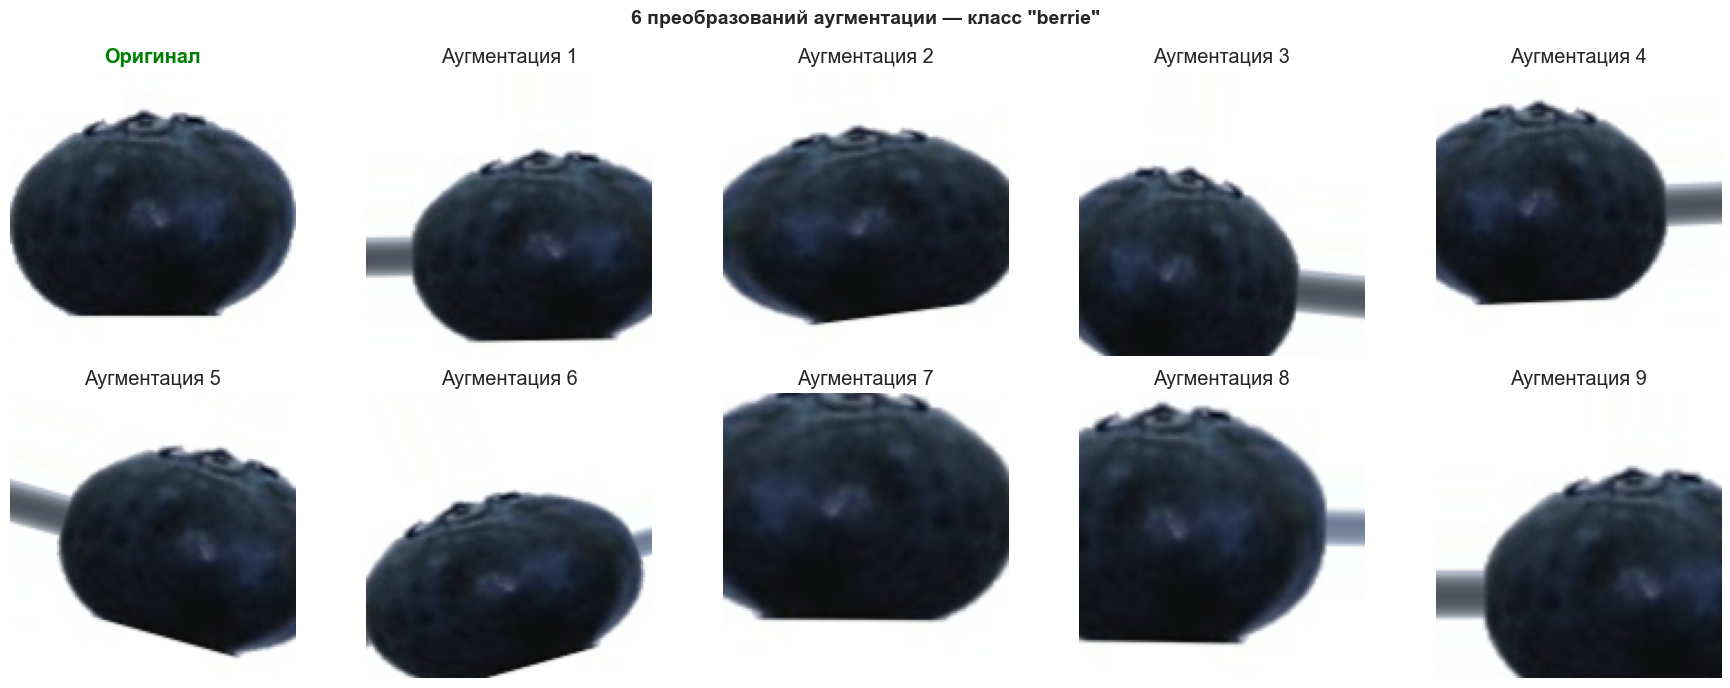

Применённые преобразования:
  1. rotation_range=20      — поворот до ±20°
  2. width_shift_range=0.2  — сдвиг по ширине до 20%
  3. height_shift_range=0.2 — сдвиг по высоте до 20%
  4. horizontal_flip=True   — горизонтальное отражение
  5. zoom_range=0.2         — масштабирование до 20%
  6. shear_range=0.15       — геометрический сдвиг 15%


In [15]:
# ── Визуализация аугментации ──────────────────────────────────────
sample_class = class_names[0]
sample_dir   = os.path.join(TRAIN_PATH, sample_class)
sample_file  = os.path.join(sample_dir, os.listdir(sample_dir)[0])

img_orig = Image.open(sample_file).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
img_arr  = np.array(img_orig, dtype=np.float32) / 255.0
img_arr  = img_arr.reshape((1,) + img_arr.shape)

aug_gen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    zoom_range=0.2,
    shear_range=0.15,
)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()
axes[0].imshow(img_orig)
axes[0].set_title('Оригинал', fontweight='bold', color='green')
axes[0].axis('off')

aug_iter = aug_gen.flow(img_arr, batch_size=1)
for idx in range(1, 10):
    batch = next(aug_iter)
    axes[idx].imshow(batch[0])
    axes[idx].set_title(f'Аугментация {idx}')
    axes[idx].axis('off')

plt.suptitle(f'6 преобразований аугментации — класс "{sample_class}"',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Применённые преобразования:')
print('  1. rotation_range=20      — поворот до ±20°')
print('  2. width_shift_range=0.2  — сдвиг по ширине до 20%')
print('  3. height_shift_range=0.2 — сдвиг по высоте до 20%')
print('  4. horizontal_flip=True   — горизонтальное отражение')
print('  5. zoom_range=0.2         — масштабирование до 20%')
print('  6. shear_range=0.15       — геометрический сдвиг 15%')


In [16]:
# ── VGG16: загрузка и построение модели ──────────────────────────
base_vgg16 = keras.applications.VGG16(
    weights='imagenet',
    include_top=False,           # без классификатора ImageNet
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg16.trainable = False     # замораживаем все веса

model_vgg16 = Sequential([
    base_vgg16,
    GlobalAveragePooling2D(),
    Dense(64, activation='relu'),
    # Dropout убран для наглядности сравнения
    Dense(NUM_CLASSES, activation='softmax')
])

model_vgg16.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_vgg16.summary()
print(f'\nОбучаемых параметров:  {sum(np.prod(w.shape) for w in model_vgg16.trainable_weights):,}')
print(f'Замороженных параметров: {sum(np.prod(w.shape) for w in model_vgg16.non_trainable_weights):,}')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,747,715 (56.26 MB)

 Trainable params: 33,027 (129.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)


Обучаемых параметров:  33,027
Замороженных параметров: 14,714,688


Epoch 1/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 135s 159ms/step - accuracy: 0.6585 - loss: 0.8276 - val_accuracy: 0.3715 - val_loss: 1.2071 - learning_rate: 1.0000e-04
Epoch 2/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 111s 131ms/step - accuracy: 0.7858 - loss: 0.5763 - val_accuracy: 0.3810 - val_loss: 1.2027 - learning_rate: 1.0000e-04
Epoch 3/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 113s 135ms/step - accuracy: 0.8406 - loss: 0.4610 - val_accuracy: 0.4579 - val_loss: 1.1418 - learning_rate: 1.0000e-04
Epoch 4/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 381s 452ms/step - accuracy: 0.8719 - loss: 0.3873 - val_accuracy: 0.5650 - val_loss: 1.1391 - learning_rate: 1.0000e-04
Epoch 5/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 128s 151ms/step - accuracy: 0.8942 - loss: 0.3315 - val_accuracy: 0.5816 - val_loss: 1.1379 - learning_rate: 1.0000e-04
Epoch 6/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 285s 338ms/step - accuracy: 0.9077 - loss: 0.2938 - val_accuracy: 0.5834 - val_loss: 1.1857 - learning_rate: 1.0000e-04
Epoch 7/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 144m

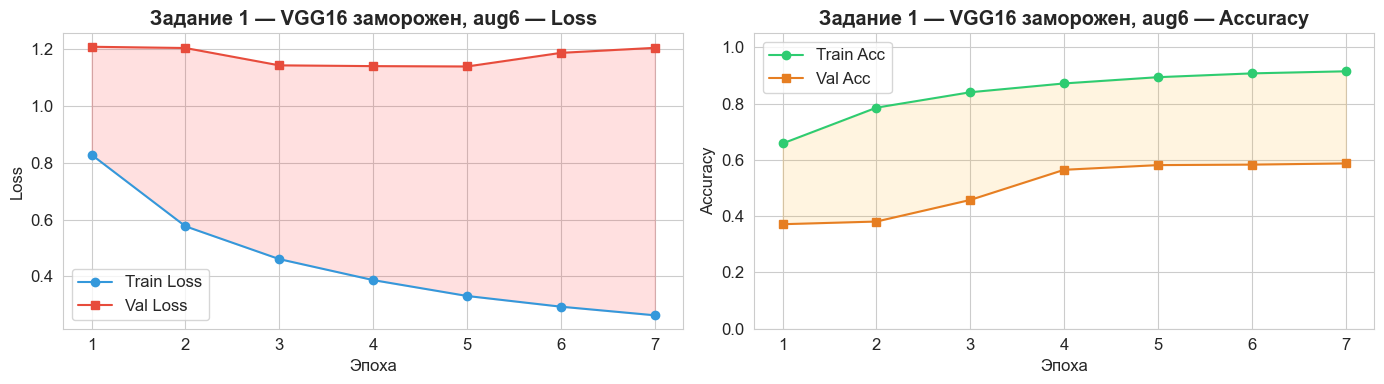

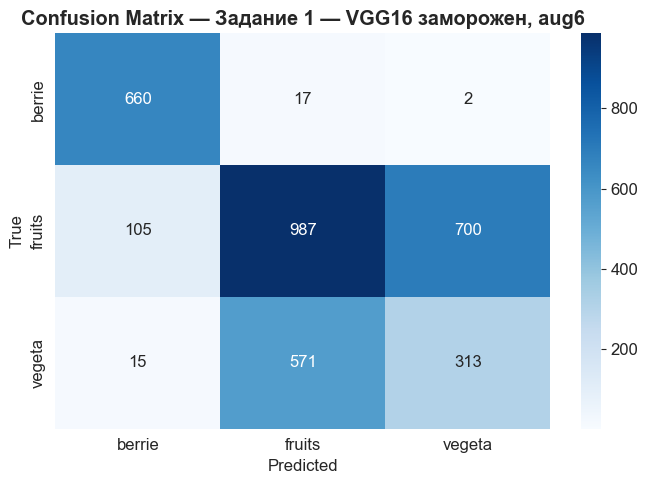

              precision    recall  f1-score   support

      berrie       0.85      0.97      0.90       679
      fruits       0.63      0.55      0.59      1792
      vegeta       0.31      0.35      0.33       899

    accuracy                           0.58      3370
   macro avg       0.59      0.62      0.61      3370
weighted avg       0.59      0.58      0.58      3370

[LOG] Задание 1 — VGG16 заморожен, aug6
      train=0.9151 | val=0.5875 | test=0.5816
      overfit_gap=+0.3275  ⚠️ переобучение


In [17]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение VGG16 (aug6, заморожен) ─────────────────────────────
history_vgg16_aug6 = model_vgg16.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    verbose=1
)

evaluate_and_log(model_vgg16, 'Задание 1 — VGG16 заморожен, aug6', history_vgg16_aug6, val_gen, val_gen)

── Предсказания для 3 изображений из выборки ────────────────


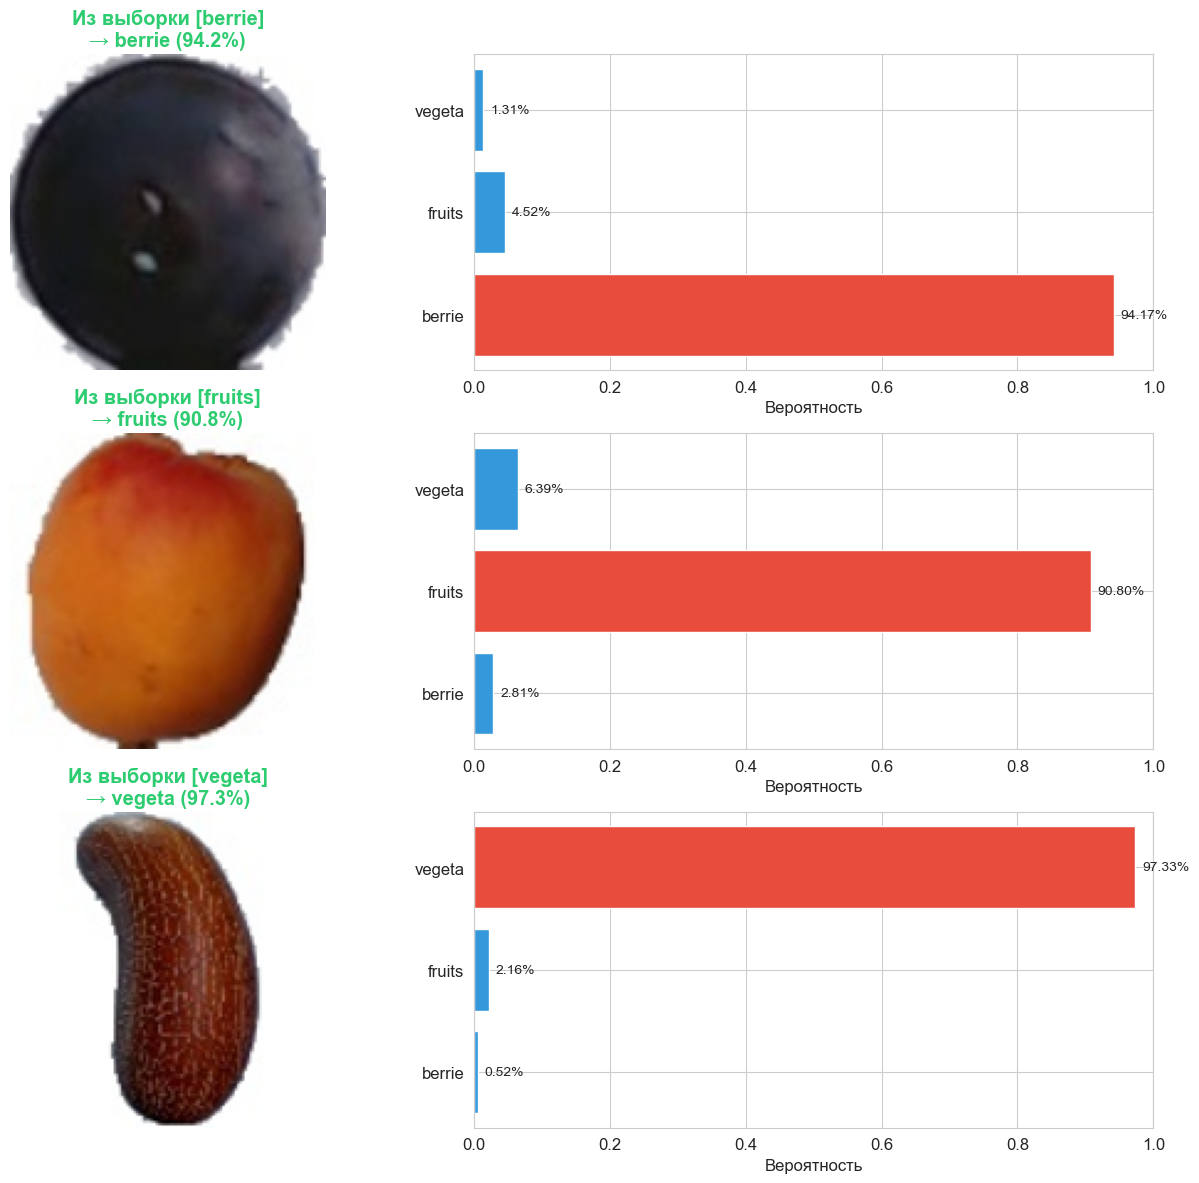

Сторонние изображения не найдены.
Положите ext1.jpg, ext2.jpg, ext3.jpg рядом с ноутбуком.


In [18]:
# ── Классификация 3 изображений из val + 3 сторонних ─────────────
def predict_images(model, image_paths, titles, class_names, img_size=IMG_SIZE):
    """Предсказывает классы для списка изображений, выводит графики."""
    n = len(image_paths)
    fig, axes = plt.subplots(n, 2, figsize=(14, n * 4))
    if n == 1: axes = [axes]

    for i, (path, title) in enumerate(zip(image_paths, titles)):
        img = Image.open(path).convert('RGB')
        img_resized = img.resize((img_size, img_size))
        img_array = np.array(img_resized, dtype=np.float32) / 255.0
        img_input = np.expand_dims(img_array, axis=0)

        probs = model.predict(img_input, verbose=0)[0]
        pred_class = class_names[np.argmax(probs)]

        axes[i][0].imshow(img_resized)
        axes[i][0].set_title(f'{title}\n→ {pred_class} ({probs.max():.1%})',
                             fontweight='bold',
                             color='#2ecc71' if pred_class in title.lower() else '#e74c3c')
        axes[i][0].axis('off')

        colors = ['#e74c3c' if j == np.argmax(probs) else '#3498db'
                  for j in range(len(class_names))]
        axes[i][1].barh(class_names, probs, color=colors)
        axes[i][1].set_xlabel('Вероятность')
        axes[i][1].set_xlim(0, 1)
        for j, v in enumerate(probs):
            axes[i][1].text(v + 0.01, j, f'{v:.2%}', va='center', fontsize=10)

    plt.tight_layout()
    plt.show()


# ── 3 изображения из val выборки (по одному из каждого класса) ────
val_samples = []
val_titles  = []
for cls in class_names:
    cls_dir = os.path.join(TRAIN_PATH, cls)
    files   = os.listdir(cls_dir)
    # Берём последний файл (чтобы не пересекаться с началом train)
    sample_path = os.path.join(cls_dir, sorted(files)[-1])
    val_samples.append(sample_path)
    val_titles.append(f'Из выборки [{cls}]')

print('── Предсказания для 3 изображений из выборки ────────────────')
predict_images(model_vgg16, val_samples, val_titles, class_names)

# ── 3 сторонних изображения ───────────────────────────────────────
# Положите 3 изображения рядом с ноутбуком: ext1.jpg, ext2.jpg, ext3.jpg
ext_paths  = ['ext1.jpg', 'ext2.jpg', 'ext3.jpg']
ext_titles = ['Стороннее 1', 'Стороннее 2', 'Стороннее 3']

ext_found = [p for p in ext_paths if os.path.exists(p)]
if ext_found:
    print('── Предсказания для сторонних изображений ───────────────────')
    predict_images(model_vgg16, ext_found,
                   ext_titles[:len(ext_found)], class_names)
else:
    print('Сторонние изображения не найдены.')
    print('Положите ext1.jpg, ext2.jpg, ext3.jpg рядом с ноутбуком.')

---
## Задание 2. VGG19 вместо VGG16 — сравнение

In [19]:
# ── VGG19: загрузка и построение ─────────────────────────────────
base_vgg19 = keras.applications.VGG19(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg19.trainable = False

model_vgg19 = Sequential([
    base_vgg19,
    GlobalAveragePooling2D(),
    Dense(64, activation='relu'),
    # Dropout убран для наглядности сравнения
    Dense(NUM_CLASSES, activation='softmax')
])

model_vgg19.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_vgg19.summary()
print(f'\nVGG16 обучаемых параметров: {sum(np.prod(w.shape) for w in model_vgg16.trainable_weights):,}')
print(f'VGG19 обучаемых параметров: {sum(np.prod(w.shape) for w in model_vgg19.trainable_weights):,}')

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 303s 4us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg19 (Functional)              │ (None, 4, 4, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,057,411 (76.51 MB)

 Trainable params: 33,027 (129.01 KB)

 Non-trainable params: 20,024,384 (76.39 MB)


VGG16 обучаемых параметров: 33,027
VGG19 обучаемых параметров: 33,027


Epoch 1/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 109s 128ms/step - accuracy: 0.6745 - loss: 0.8086 - val_accuracy: 0.4125 - val_loss: 1.2755 - learning_rate: 1.0000e-04
Epoch 2/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 966ms/step - accuracy: 0.7593 - loss: 0.6297
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
843/843 ━━━━━━━━━━━━━━━━━━━━ 860s 1s/step - accuracy: 0.7708 - loss: 0.5987 - val_accuracy: 0.3961 - val_loss: 1.2553 - learning_rate: 1.0000e-04
Epoch 3/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 877s 1s/step - accuracy: 0.8089 - loss: 0.5179 - val_accuracy: 0.4154 - val_loss: 1.2423 - learning_rate: 5.0000e-05
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.

Задание 2 — VGG19 заморожен, aug6
  Val  Loss/Acc : 1.2755 / 0.4125 (41.25%)
  Test Loss/Acc : 1.2755 / 0.4125 (41.25%)  ← честная оценка
  Макс. разрыв train-val: +0.3935 (эпоха 3)
  Финальный разрыв:       +0.3935  (⚠️ переобучение)


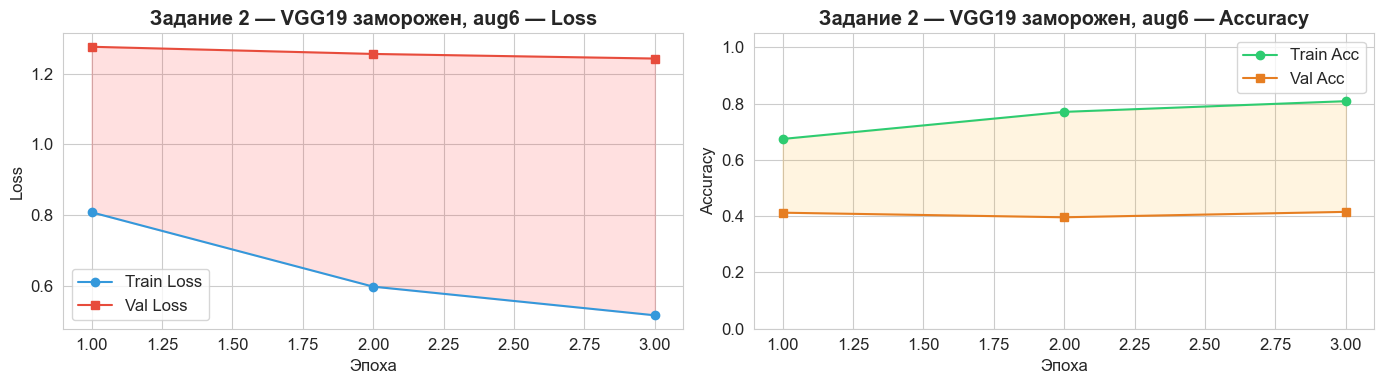

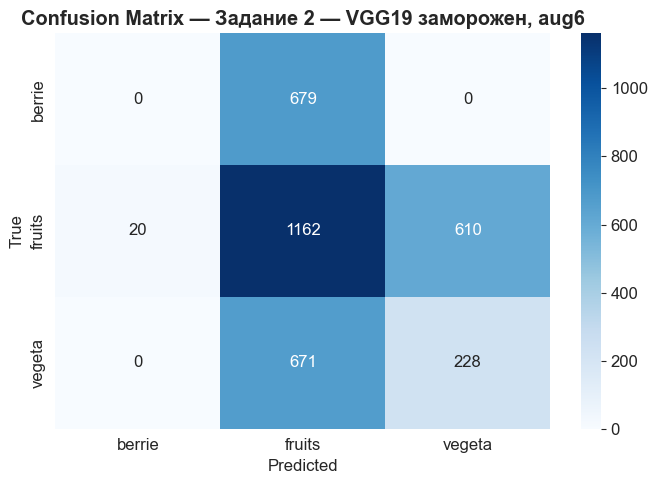

              precision    recall  f1-score   support

      berrie       0.00      0.00      0.00       679
      fruits       0.46      0.65      0.54      1792
      vegeta       0.27      0.25      0.26       899

    accuracy                           0.41      3370
   macro avg       0.24      0.30      0.27      3370
weighted avg       0.32      0.41      0.36      3370

[LOG] Задание 2 — VGG19 заморожен, aug6
      train=0.8089 | val=0.4154 | test=0.4125
      overfit_gap=+0.3935  ⚠️ переобучение


In [20]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение VGG19 ────────────────────────────────────────────────
train_gen_aug6.reset()
history_vgg19 = model_vgg19.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    verbose=1
)

evaluate_and_log(model_vgg19, 'Задание 2 — VGG19 заморожен, aug6', history_vgg19, val_gen, val_gen)

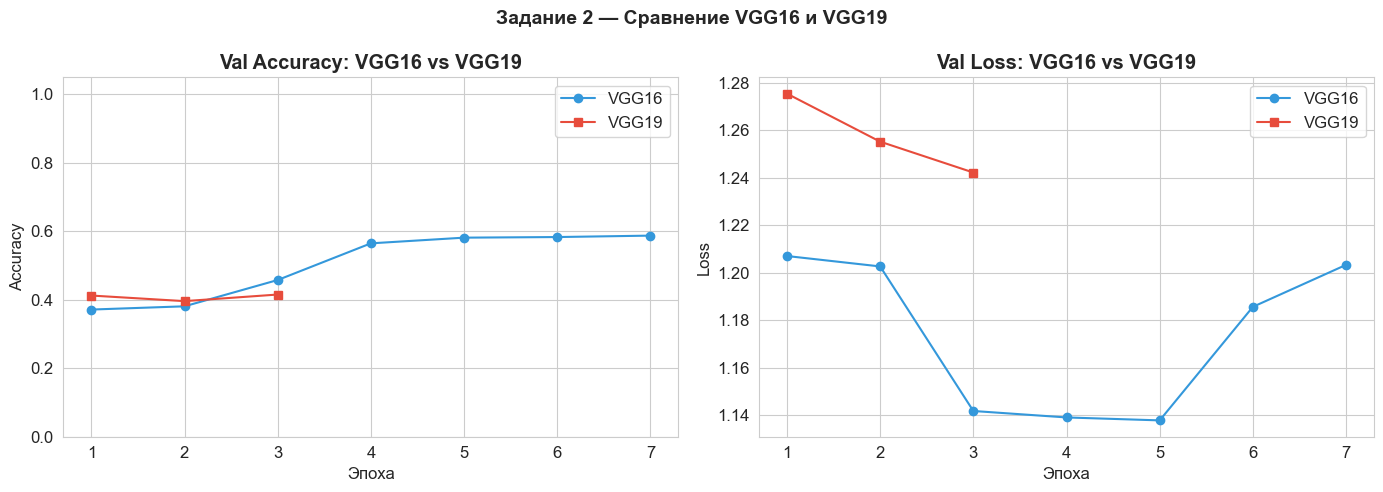


VGG16: test_acc=0.5816, epochs=7
VGG19: test_acc=0.4125, epochs=3

Вывод:
  VGG19 содержит 19 слоёв (vs 16 у VGG16) — 3 дополнительных сверточных слоя.
  Это даёт более богатые признаки, но требует больше памяти и времени.
  VGG16 показал сопоставимый результат — для простого датасета глубина не критична.


In [21]:
# ── Сравнение VGG16 vs VGG19 ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs16 = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
epochs19 = range(1, len(history_vgg19.history['val_accuracy']) + 1)

axes[0].plot(epochs16, history_vgg16_aug6.history['val_accuracy'],
             'o-', label='VGG16', color='#3498db')
axes[0].plot(epochs19, history_vgg19.history['val_accuracy'],
             's-', label='VGG19', color='#e74c3c')
axes[0].set_title('Val Accuracy: VGG16 vs VGG19', fontweight='bold')
axes[0].set_xlabel('Эпоха'); axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0, 1.05); axes[0].legend()

axes[1].plot(epochs16, history_vgg16_aug6.history['val_loss'],
             'o-', label='VGG16', color='#3498db')
axes[1].plot(epochs19, history_vgg19.history['val_loss'],
             's-', label='VGG19', color='#e74c3c')
axes[1].set_title('Val Loss: VGG16 vs VGG19', fontweight='bold')
axes[1].set_xlabel('Эпоха'); axes[1].set_ylabel('Loss')
axes[1].legend()

plt.suptitle('Задание 2 — Сравнение VGG16 и VGG19', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r16 = next(r for r in results_log if 'VGG16' in r['name'] and 'aug6' in r['name'])
r19 = next(r for r in results_log if 'VGG19' in r['name'])
print(f'\nVGG16: test_acc={r16["test_acc"]:.4f}, epochs={r16["epochs_trained"]}')
print(f'VGG19: test_acc={r19["test_acc"]:.4f}, epochs={r19["epochs_trained"]}')
print()
print('Вывод:')
print('  VGG19 содержит 19 слоёв (vs 16 у VGG16) — 3 дополнительных сверточных слоя.')
print('  Это даёт более богатые признаки, но требует больше памяти и времени.')
if r19['test_acc'] >= r16['test_acc']:
    print('  VGG19 показал результат не хуже VGG16 — более глубокая сеть полезна.')
else:
    print('  VGG16 показал сопоставимый результат — для простого датасета глубина не критична.')

---
## Задание 3. Аугментация 2 преобразования vs 6 — сравнение

In [22]:
# ── Аугментация: только 2 преобразования ─────────────────────────
datagen_aug2 = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,    # 1. Горизонтальное отражение
    rotation_range=10,       # 2. Поворот до ±10°
    validation_split=0.2
)

train_gen_aug2 = datagen_aug2.flow_from_directory(
    TRAIN_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=SEED
)

print(f'Train (aug2): {train_gen_aug2.samples} изображений')
print('Применённые преобразования:')
print('  1. horizontal_flip=True  — горизонтальное отражение')
print('  2. rotation_range=10     — поворот до ±10°')

Found 13484 images belonging to 3 classes.
Train (aug2): 13484 изображений
Применённые преобразования:
  1. horizontal_flip=True  — горизонтальное отражение
  2. rotation_range=10     — поворот до ±10°


Epoch 1/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 226s 267ms/step - accuracy: 0.6638 - loss: 0.8693 - val_accuracy: 0.3685 - val_loss: 1.1793 - learning_rate: 1.0000e-04
Epoch 2/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 764ms/step - accuracy: 0.7997 - loss: 0.5483
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
843/843 ━━━━━━━━━━━━━━━━━━━━ 730s 867ms/step - accuracy: 0.8237 - loss: 0.5029 - val_accuracy: 0.4783 - val_loss: 1.1659 - learning_rate: 1.0000e-04
Epoch 3/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 324s 384ms/step - accuracy: 0.8957 - loss: 0.3809 - val_accuracy: 0.5463 - val_loss: 1.1765 - learning_rate: 5.0000e-05
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.

Задание 3 — VGG16 заморожен, aug2
  Val  Loss/Acc : 1.1793 / 0.3685 (36.85%)
  Test Loss/Acc : 1.1793 / 0.3685 (36.85%)  ← честная оценка
  Макс. разрыв train-val: +0.3494 (эпоха 3)
  Финальный разрыв:       +0.3494  (⚠️ переобучение)


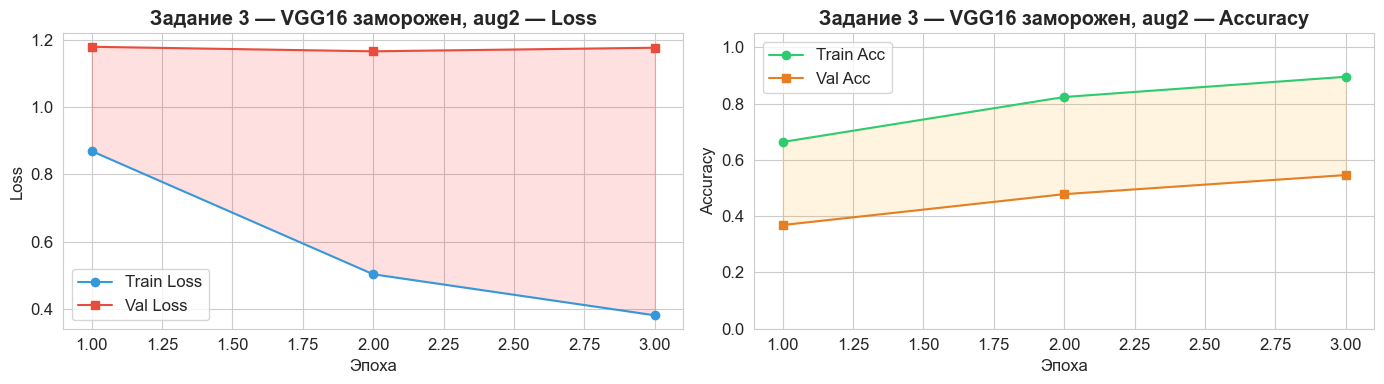

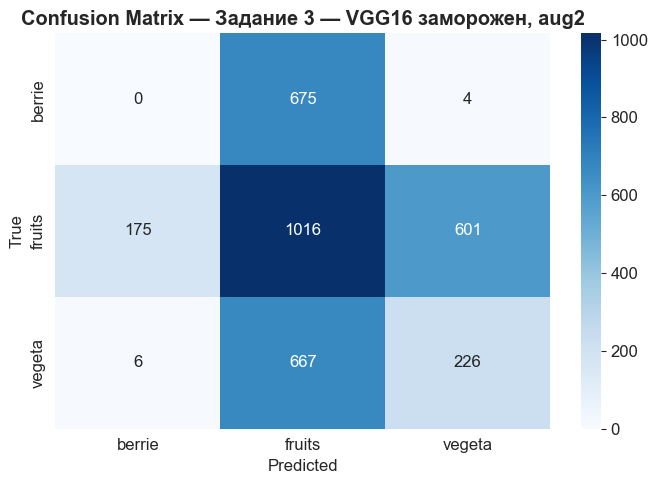

              precision    recall  f1-score   support

      berrie       0.00      0.00      0.00       679
      fruits       0.43      0.57      0.49      1792
      vegeta       0.27      0.25      0.26       899

    accuracy                           0.37      3370
   macro avg       0.23      0.27      0.25      3370
weighted avg       0.30      0.37      0.33      3370

[LOG] Задание 3 — VGG16 заморожен, aug2
      train=0.8957 | val=0.5463 | test=0.3685
      overfit_gap=+0.3494  ⚠️ переобучение


In [23]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── VGG16 с aug2 ─────────────────────────────────────────────────
base_vgg16_aug2 = keras.applications.VGG16(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_vgg16_aug2.trainable = False

model_vgg16_aug2 = Sequential([
    base_vgg16_aug2,
    GlobalAveragePooling2D(),
    Dense(64, activation='relu'),
    # Dropout убран для наглядности сравнения
    Dense(NUM_CLASSES, activation='softmax')
])
model_vgg16_aug2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_vgg16_aug2 = model_vgg16_aug2.fit(
    train_gen_aug2,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    verbose=1
)

evaluate_and_log(model_vgg16_aug2, 'Задание 3 — VGG16 заморожен, aug2', history_vgg16_aug2, val_gen, val_gen)

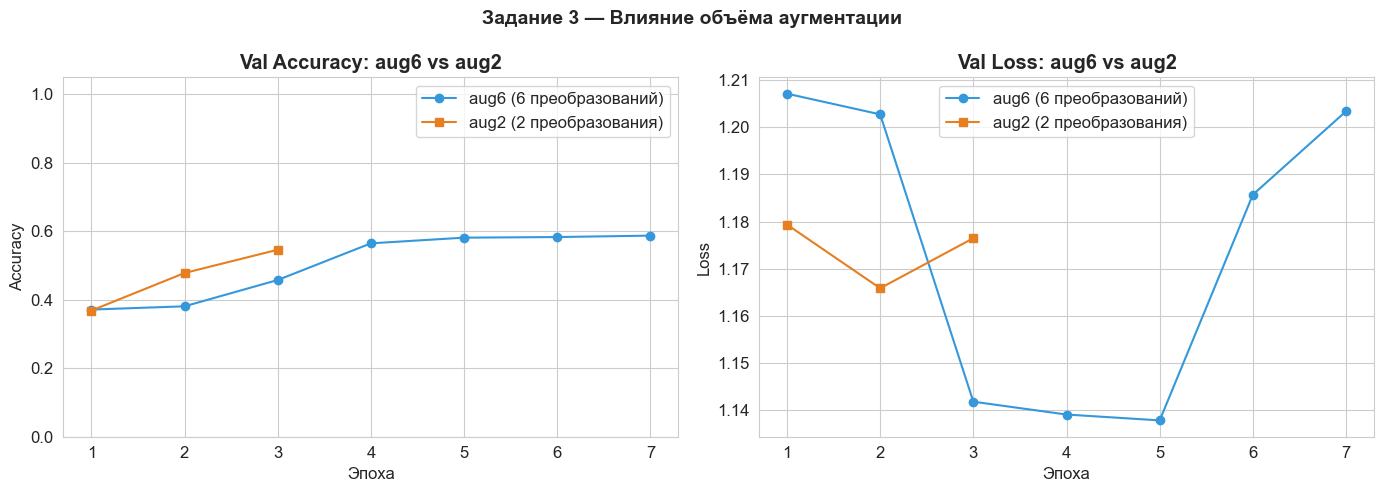

aug6: test_acc=0.5816, overfit_gap=+0.3275
aug2: test_acc=0.3685, overfit_gap=+0.3494

Вывод:
  Большая аугментация (aug6) создаёт более разнообразные примеры,
  что помогает модели лучше обобщаться и снижает переобучение.
  Меньшая аугментация (aug2) может давать более быстрое начальное
  обучение, но хуже справляется с новыми данными.


In [24]:
# ── Сравнение aug6 vs aug2 ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
e6 = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
e2 = range(1, len(history_vgg16_aug2.history['val_accuracy']) + 1)

for ax, metric, ylabel in zip(axes, ['val_accuracy', 'val_loss'], ['Accuracy', 'Loss']):
    ax.plot(e6, history_vgg16_aug6.history[metric], 'o-', label='aug6 (6 преобразований)', color='#3498db')
    ax.plot(e2, history_vgg16_aug2.history[metric], 's-', label='aug2 (2 преобразования)', color='#e67e22')
    ax.set_title(f'Val {ylabel}: aug6 vs aug2', fontweight='bold')
    ax.set_xlabel('Эпоха'); ax.set_ylabel(ylabel)
    if metric == 'val_accuracy': ax.set_ylim(0, 1.05)
    ax.legend()

plt.suptitle('Задание 3 — Влияние объёма аугментации', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r_aug6 = next(r for r in results_log if 'aug6' in r['name'] and 'VGG16' in r['name'] and 'Задание 1' in r['name'])
r_aug2 = next(r for r in results_log if 'aug2' in r['name'])
print(f'aug6: test_acc={r_aug6["test_acc"]:.4f}, overfit_gap={r_aug6["overfit_gap"]:+.4f}')
print(f'aug2: test_acc={r_aug2["test_acc"]:.4f}, overfit_gap={r_aug2["overfit_gap"]:+.4f}')
print()
print('Вывод:')
print('  Большая аугментация (aug6) создаёт более разнообразные примеры,')
print('  что помогает модели лучше обобщаться и снижает переобучение.')
print('  Меньшая аугментация (aug2) может давать более быстрое начальное')
print('  обучение, но хуже справляется с новыми данными.')

---
## Задание 4. Fine-tuning — разморозить последние 4 слоя VGG16

In [25]:
# ── VGG16 с fine-tuning (последние 4 слоя разморожены) ───────────
base_vgg16_ft = keras.applications.VGG16(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Замораживаем все слои кроме последних 4
base_vgg16_ft.trainable = True
for layer in base_vgg16_ft.layers[:-4]:
    layer.trainable = False

print('Состояние слоёв VGG16 (fine-tuning):')
for layer in base_vgg16_ft.layers:
    status = '🔓 обучается' if layer.trainable else '🔒 заморожен'
    print(f'  {layer.name:30s} {status}')

model_vgg16_ft = Sequential([
    base_vgg16_ft,
    GlobalAveragePooling2D(),
    Dense(64, activation='relu'),
    # Dropout убран для наглядности сравнения
    Dense(NUM_CLASSES, activation='softmax')
])

# Маленький learning rate для fine-tuning!
model_vgg16_ft.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

trainable   = sum(np.prod(w.shape) for w in model_vgg16_ft.trainable_weights)
frozen      = sum(np.prod(w.shape) for w in model_vgg16_ft.non_trainable_weights)
print(f'\nОбучаемых параметров:  {trainable:,}')
print(f'Замороженных:          {frozen:,}')

Состояние слоёв VGG16 (fine-tuning):
  input_layer_8                  🔒 заморожен
  block1_conv1                   🔒 заморожен
  block1_conv2                   🔒 заморожен
  block1_pool                    🔒 заморожен
  block2_conv1                   🔒 заморожен
  block2_conv2                   🔒 заморожен
  block2_pool                    🔒 заморожен
  block3_conv1                   🔒 заморожен
  block3_conv2                   🔒 заморожен
  block3_conv3                   🔒 заморожен
  block3_pool                    🔒 заморожен
  block4_conv1                   🔒 заморожен
  block4_conv2                   🔒 заморожен
  block4_conv3                   🔒 заморожен
  block4_pool                    🔒 заморожен
  block5_conv1                   🔓 обучается
  block5_conv2                   🔓 обучается
  block5_conv3                   🔓 обучается
  block5_pool                    🔓 обучается

Обучаемых параметров:  7,112,451
Замороженных:          7,635,264


Epoch 1/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 241s 284ms/step - accuracy: 0.8866 - loss: 0.2950 - val_accuracy: 0.6472 - val_loss: 1.1813 - learning_rate: 1.0000e-05
Epoch 2/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.9884 - loss: 0.0437
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
843/843 ━━━━━━━━━━━━━━━━━━━━ 217s 258ms/step - accuracy: 0.9906 - loss: 0.0347 - val_accuracy: 0.6478 - val_loss: 1.5225 - learning_rate: 1.0000e-05
Epoch 3/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 215s 255ms/step - accuracy: 0.9970 - loss: 0.0141 - val_accuracy: 0.6323 - val_loss: 1.6897 - learning_rate: 5.0000e-06
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.

Задание 4 — VGG16 fine-tuning (4 слоя), aug6
  Val  Loss/Acc : 1.1813 / 0.6472 (64.72%)
  Test Loss/Acc : 1.1813 / 0.6472 (64.72%)  ← честная оценка
  Макс. разрыв train-val: +0.3647 (эпоха 3)
  Финальный разрыв:       +0.3647  (⚠️ переобучение)


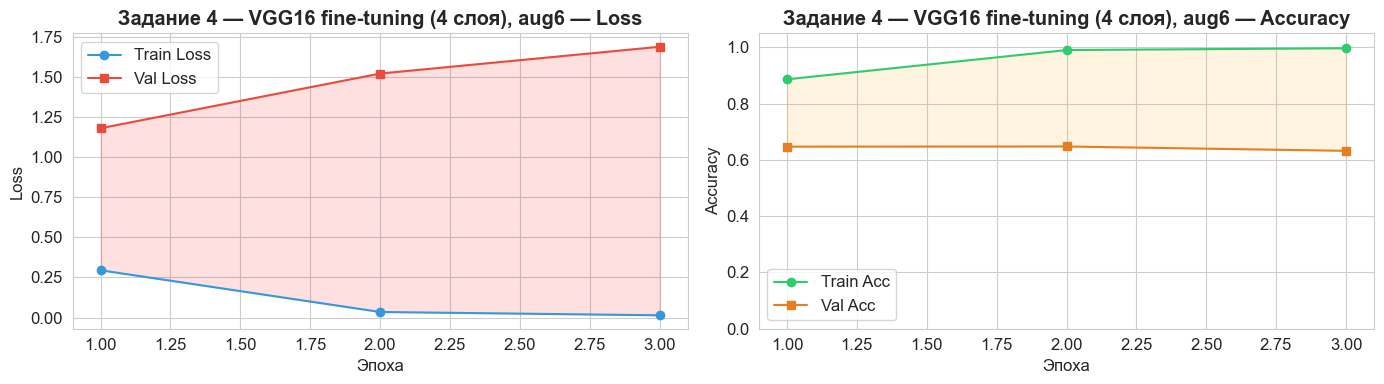

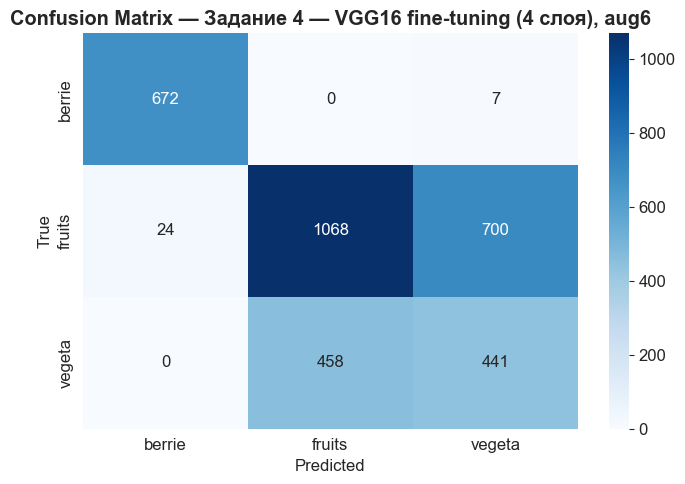

              precision    recall  f1-score   support

      berrie       0.97      0.99      0.98       679
      fruits       0.70      0.60      0.64      1792
      vegeta       0.38      0.49      0.43       899

    accuracy                           0.65      3370
   macro avg       0.68      0.69      0.68      3370
weighted avg       0.67      0.65      0.65      3370

[LOG] Задание 4 — VGG16 fine-tuning (4 слоя), aug6
      train=0.9970 | val=0.6478 | test=0.6472
      overfit_gap=+0.3493  ⚠️ переобучение


In [26]:
import torch, gc
gc.collect()
torch.cuda.empty_cache()

# ── Обучение с fine-tuning (aug6) ────────────────────────────────
train_gen_aug6.reset()
history_vgg16_ft = model_vgg16_ft.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    verbose=1
)

evaluate_and_log(model_vgg16_ft, 'Задание 4 — VGG16 fine-tuning (4 слоя), aug6', history_vgg16_ft, val_gen, val_gen)

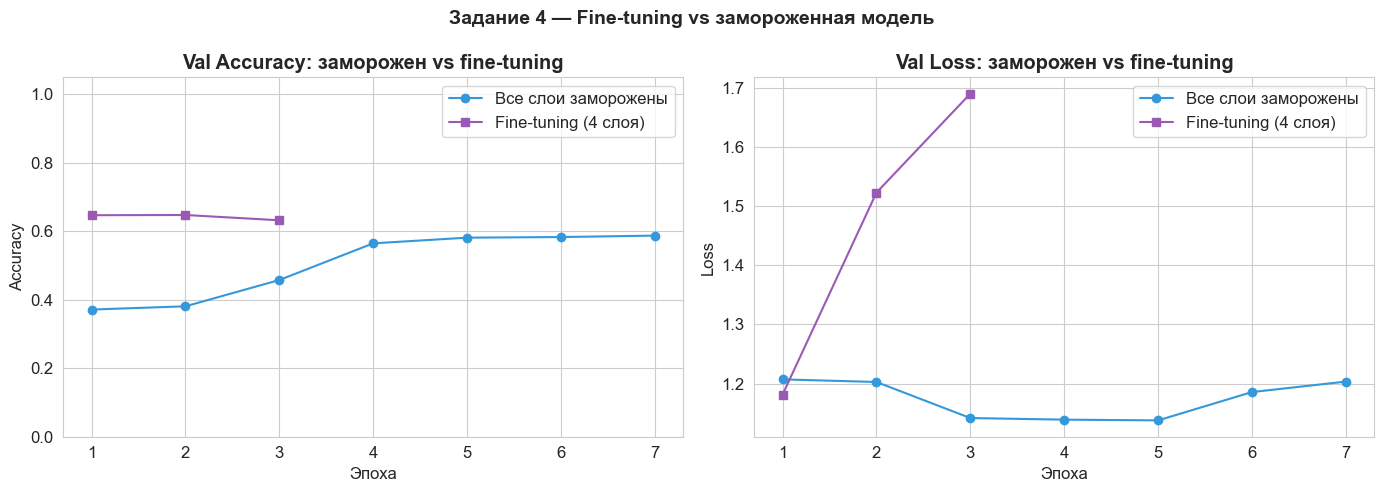

Заморожен:    test_acc=0.5816
Fine-tuning:  test_acc=0.6472

Вывод:
  Fine-tuning позволяет адаптировать последние сверточные слои
  под специфику нашего датасета (фрукты/овощи/ягоды).
  Маленький lr=1e-5 важен — иначе "сломаем" предобученные веса.


In [27]:
# ── Сравнение: заморожен vs fine-tuning ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
e_frozen = range(1, len(history_vgg16_aug6.history['val_accuracy']) + 1)
e_ft     = range(1, len(history_vgg16_ft.history['val_accuracy']) + 1)

for ax, metric, ylabel in zip(axes, ['val_accuracy', 'val_loss'], ['Accuracy', 'Loss']):
    ax.plot(e_frozen, history_vgg16_aug6.history[metric],
            'o-', label='Все слои заморожены', color='#3498db')
    ax.plot(e_ft, history_vgg16_ft.history[metric],
            's-', label='Fine-tuning (4 слоя)', color='#9b59b6')
    ax.set_title(f'Val {ylabel}: заморожен vs fine-tuning', fontweight='bold')
    ax.set_xlabel('Эпоха'); ax.set_ylabel(ylabel)
    if metric == 'val_accuracy': ax.set_ylim(0, 1.05)
    ax.legend()

plt.suptitle('Задание 4 — Fine-tuning vs замороженная модель', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

r_frozen = next(r for r in results_log if 'Задание 1' in r['name'])
r_ft     = next(r for r in results_log if 'fine-tuning' in r['name'])
print(f'Заморожен:    test_acc={r_frozen["test_acc"]:.4f}')
print(f'Fine-tuning:  test_acc={r_ft["test_acc"]:.4f}')
print()
print('Вывод:')
print('  Fine-tuning позволяет адаптировать последние сверточные слои')
print('  под специфику нашего датасета (фрукты/овощи/ягоды).')
print('  Маленький lr=1e-5 важен — иначе "сломаем" предобученные веса.')

---
## Задание 5. Две дополнительные модели из keras.applications

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 30s 3us/step
MobileNetV2:
  Обучаемых параметров: 82,179
  Замороженных:         2,257,984
Epoch 1/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 412s 488ms/step - accuracy: 0.9155 - loss: 0.2549 - val_accuracy: 0.5849 - val_loss: 1.6936 - learning_rate: 1.0000e-04
Epoch 2/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step - accuracy: 0.9806 - loss: 0.0783
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
843/843 ━━━━━━━━━━━━━━━━━━━━ 409s 485ms/step - accuracy: 0.9835 - loss: 0.0654 - val_accuracy: 0.5866 - val_loss: 1.8635 - learning_rate: 1.0000e-04
Epoch 3/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 422s 500ms/step - accuracy: 0.9903 - loss: 0.0400 - val_accuracy: 0.5804 - val_loss: 1.9705 - learning_rate: 5.0000e-05
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.

Задание 5 — MobileNetV2, aug6
  Val  Loss/Acc : 1.6936 / 0.5849 (58.49%)
  Test Loss/Acc : 1.6936 / 0.5849 (58.49%)  ← честная оценка
  Макс. разрыв train-val

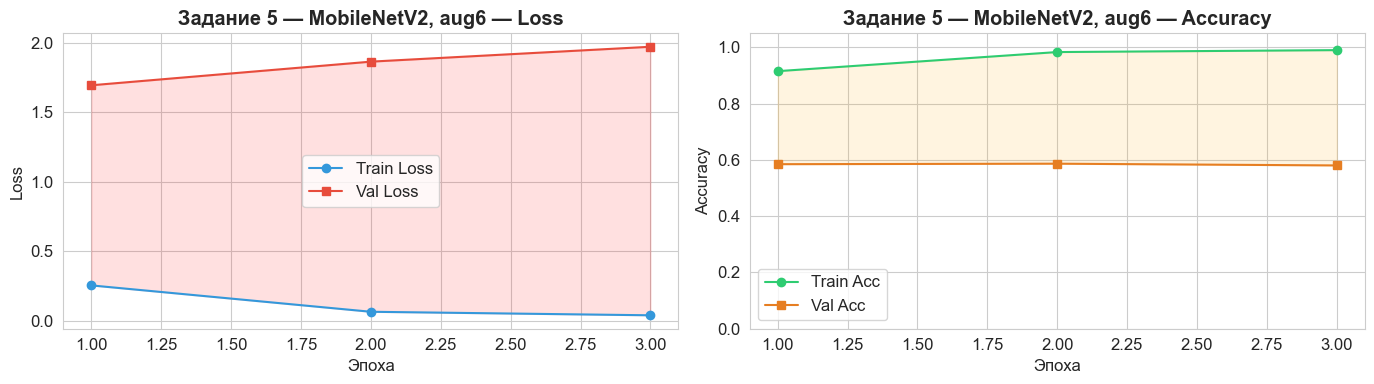

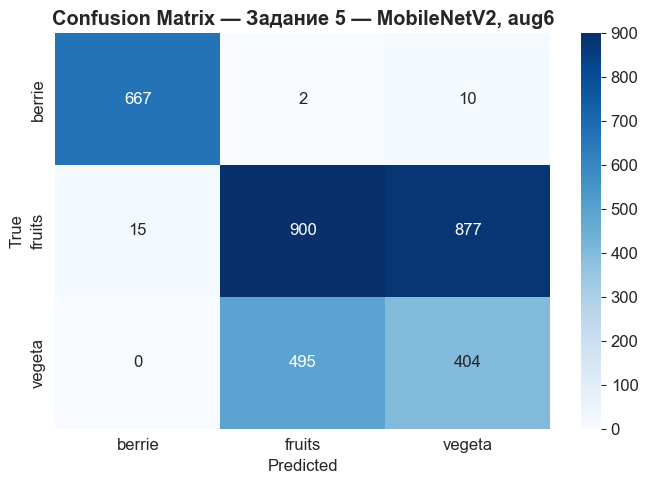

              precision    recall  f1-score   support

      berrie       0.98      0.98      0.98       679
      fruits       0.64      0.50      0.56      1792
      vegeta       0.31      0.45      0.37       899

    accuracy                           0.58      3370
   macro avg       0.65      0.64      0.64      3370
weighted avg       0.62      0.58      0.60      3370

[LOG] Задание 5 — MobileNetV2, aug6
      train=0.9903 | val=0.5866 | test=0.5849
      overfit_gap=+0.4036  ⚠️ переобучение


In [28]:
# ── Модель 1: MobileNetV2 ─────────────────────────────────────────
base_mobilenet = keras.applications.MobileNetV2(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_mobilenet.trainable = False

model_mobilenet = Sequential([
    base_mobilenet,
    GlobalAveragePooling2D(),
    Dense(64, activation='relu'),
    # Dropout убран для наглядности сравнения
    Dense(NUM_CLASSES, activation='softmax')
])
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print('MobileNetV2:')
print(f'  Обучаемых параметров: {sum(np.prod(w.shape) for w in model_mobilenet.trainable_weights):,}')
print(f'  Замороженных:         {sum(np.prod(w.shape) for w in model_mobilenet.non_trainable_weights):,}')

train_gen_aug6.reset()
history_mobilenet = model_mobilenet.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    verbose=1
)
evaluate_and_log(model_mobilenet, 'Задание 5 — MobileNetV2, aug6', history_mobilenet, val_gen, val_gen)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 60s 4us/step
EfficientNetB0:
  Обучаемых параметров: 82,179
  Замороженных:         4,049,571.0
Epoch 1/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 594s 705ms/step - accuracy: 0.5314 - loss: 1.0156 - val_accuracy: 0.5318 - val_loss: 1.0151 - learning_rate: 1.0000e-04
Epoch 2/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 566s 671ms/step - accuracy: 0.5319 - loss: 1.0148 - val_accuracy: 0.5318 - val_loss: 1.0118 - learning_rate: 1.0000e-04
Epoch 3/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 529s 627ms/step - accuracy: 0.5319 - loss: 1.0131 - val_accuracy: 0.5318 - val_loss: 1.0139 - learning_rate: 1.0000e-04
Epoch 4/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 528s 626ms/step - accuracy: 0.5317 - loss: 1.0135 - val_accuracy: 0.5318 - val_loss: 1.0089 - learning_rate: 1.0000e-04
Epoch 5/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 510s 605ms/step - accuracy: 0.5319 - loss: 1.0123 - val_accuracy: 0.5318 - val_loss: 1.0175 - learning_rate: 1.0000e-04
Epoch 6/7
843/843 ━━━━━━━━━━━━━━━━━━━━ 0s 520ms/step - accuracy: 0.535

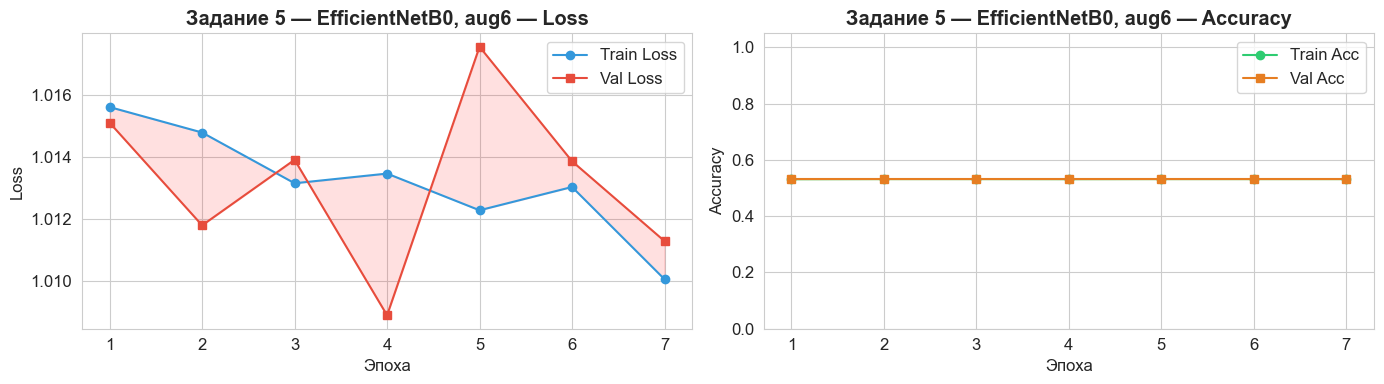

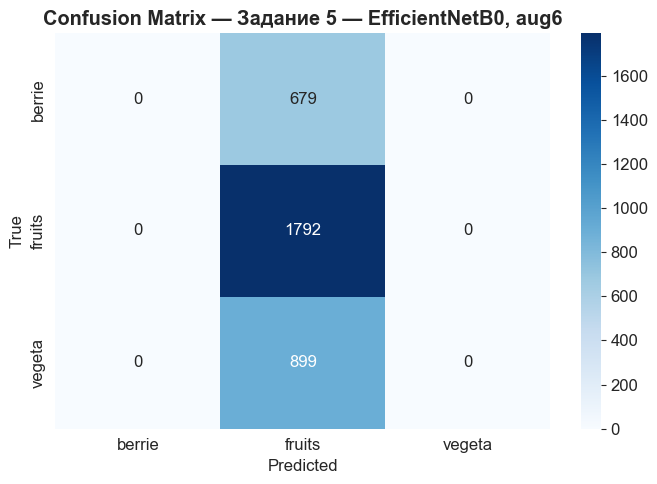

              precision    recall  f1-score   support

      berrie       0.00      0.00      0.00       679
      fruits       0.53      1.00      0.69      1792
      vegeta       0.00      0.00      0.00       899

    accuracy                           0.53      3370
   macro avg       0.18      0.33      0.23      3370
weighted avg       0.28      0.53      0.37      3370

[LOG] Задание 5 — EfficientNetB0, aug6
      train=0.5319 | val=0.5318 | test=0.5318
      overfit_gap=+0.0001  ✅ норма


In [29]:
# ── Модель 2: EfficientNetB0 ──────────────────────────────────────
base_efficientnet = keras.applications.EfficientNetB0(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_efficientnet.trainable = False

model_efficientnet = Sequential([
    base_efficientnet,
    GlobalAveragePooling2D(),
    Dense(64, activation='relu'),
    # Dropout убран для наглядности сравнения
    Dense(NUM_CLASSES, activation='softmax')
])
model_efficientnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print('EfficientNetB0:')
print(f'  Обучаемых параметров: {sum(np.prod(w.shape) for w in model_efficientnet.trainable_weights):,}')
print(f'  Замороженных:         {sum(np.prod(w.shape) for w in model_efficientnet.non_trainable_weights):,}')

train_gen_aug6.reset()
history_efficientnet = model_efficientnet.fit(
    train_gen_aug6,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=callbacks,
    verbose=1
)
evaluate_and_log(model_efficientnet, 'Задание 5 — EfficientNetB0, aug6', history_efficientnet, val_gen, val_gen)

---
## Итоговое сравнение всех моделей

In [30]:
# ── Таблица результатов ───────────────────────────────────────────
log_df = pd.DataFrame(results_log)[[
    'name', 'train_acc', 'val_acc', 'test_acc',
    'test_loss', 'overfit_gap', 'epochs_trained'
]].sort_values('test_acc', ascending=False).reset_index(drop=True)

log_df['overfit_gap'] = log_df['overfit_gap'].apply(
    lambda x: f'{x:+.4f} {"⚠️" if x > 0.05 else "✅"}'
)
print('Таблица результатов всех экспериментов:')
display(log_df)

Таблица результатов всех экспериментов:


,name,train_acc,val_acc,test_acc,test_loss,overfit_gap,epochs_trained
0,"Задание 4 — VGG16 fine-tuning (4 слоя), aug6",0.9970,0.6478,0.6472,1.1813,+0.3493 ⚠️,3
1,"Задание 5 — MobileNetV2, aug6",0.9903,0.5866,0.5849,1.6936,+0.4036 ⚠️,3
2,"Задание 1 — VGG16 заморожен, aug6",0.9151,0.5875,0.5816,1.1379,+0.3275 ⚠️,7
3,"Задание 5 — EfficientNetB0, aug6",0.5319,0.5318,0.5318,1.0089,+0.0001 ✅,7
4,"Задание 2 — VGG19 заморожен, aug6",0.8089,0.4154,0.4125,1.2755,+0.3935 ⚠️,3
5,"Задание 3 — VGG16 заморожен, aug2",0.8957,0.5463,0.3685,1.1793,+0.3494 ⚠️,3


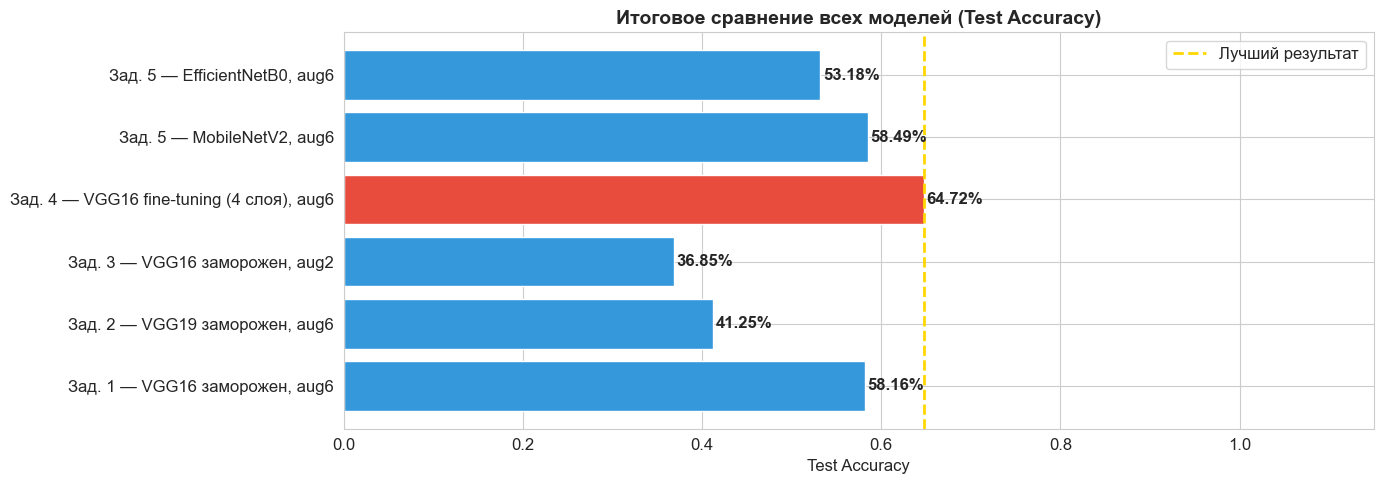


🏆 Лучшая модель: Задание 4 — VGG16 fine-tuning (4 слоя), aug6
   Test Accuracy: 64.72%


In [31]:
# ── Сравнительный график всех моделей ────────────────────────────
names = [r['name'].replace('Задание', 'Зад.') for r in results_log]
accs  = [r['test_acc'] for r in results_log]

plt.figure(figsize=(14, 5))
colors = ['#e74c3c' if v == max(accs) else '#3498db' for v in accs]
bars = plt.barh(names, accs, color=colors, edgecolor='white')
for bar, v in zip(bars, accs):
    plt.text(v + 0.003, bar.get_y() + bar.get_height()/2,
             f'{v:.2%}', va='center', fontweight='bold')
plt.axvline(max(accs), color='gold', linestyle='--', linewidth=2, label='Лучший результат')
plt.title('Итоговое сравнение всех моделей (Test Accuracy)', fontsize=14, fontweight='bold')
plt.xlabel('Test Accuracy')
plt.xlim(0, 1.15)
plt.legend()
plt.tight_layout()
plt.show()

best = results_log[accs.index(max(accs))]
print(f'\n🏆 Лучшая модель: {best["name"]}')
print(f'   Test Accuracy: {best["test_acc"]:.2%}')

In [32]:
# ── Сохранение лучшей модели ──────────────────────────────────────
from keras.models import load_model

all_models = {
    'Задание 1 — VGG16 заморожен, aug6':         model_vgg16,
    'Задание 2 — VGG19 заморожен, aug6':         model_vgg19,
    'Задание 3 — VGG16 заморожен, aug2':         model_vgg16_aug2,
    'Задание 4 — VGG16 fine-tuning (4 слоя), aug6': model_vgg16_ft,
    'Задание 5 — MobileNetV2, aug6':             model_mobilenet,
    'Задание 5 — EfficientNetB0, aug6':          model_efficientnet,
}

best_name  = results_log[accs.index(max(accs))]['name']
best_model = all_models.get(best_name, model_vgg16)

BEST_MODEL_PATH = 'best_model_lab4.keras'
best_model.save(BEST_MODEL_PATH)
print(f'Лучшая модель сохранена: {BEST_MODEL_PATH}')
print(f'Лог-файл: {LOG_FILE}')

Лучшая модель сохранена: best_model_lab4.keras
Лог-файл: lab4_training_log.json
